Assignment 10 rollno 1024170249


In [1]:
import nltk, re, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support

for p in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(p, quiet=True)

## 1. Labelled Corpus

In [2]:
corpus = {
    "symptoms": [
        "how do i identify early symptoms of diabetes",
        "what are the key indicators of high glucose",
        "why do i feel constantly thirsty and tired",
        "are there clear warning signs for type 2 diabetes",
        "could blurred vision be a sign of diabetes",
        "what happens during a low blood sugar episode",
        "frequent urination and weight loss indicators",
        "how does one spot diabetes early on",
        "what are the classic physical signs of diabetes",
    ],
    "diet": [
        "what is the best meal plan for diabetes control",
        "which foods should be avoided by diabetics",
        "is it safe for a diabetic to eat brown rice",
        "which fruits are recommended for high blood sugar",
        "healthy breakfast choices for diabetic patients",
        "how to manage daily carbohydrate intake",
        "can diabetics consume sweets in moderation",
        "nutrition tips for stabilizing glucose levels",
        "are sugar-free products truly safe for diabetics",
        "what snacks keep my blood sugar stable",
    ],
    "medication": [
        "what are the common prescriptions for diabetes",
        "explain how metformin lowers blood sugar",
        "what are the primary side effects of diabetes drugs",
        "when is insulin therapy initiated",
        "what are the different types of insulin available",
        "what should I do if I miss my diabetic medication",
        "proper storage instructions for insulin pens",
        "is insulin mandatory for type 2 diabetes patients",
        "step-by-step guide to injecting insulin",
    ],
    "monitoring": [
        "what ranges are considered normal for blood sugar",
        "how frequently must I test my glucose levels",
        "what does the hba1c test actually measure",
        "how to correctly operate a home glucometer",
        "what is a healthy fasting glucose level",
        "target blood sugar levels two hours after meals",
        "what is an optimal hba1c goal for diabetics",
        "best practices for tracking blood sugar readings",
        "benefits of using a continuous glucose monitor",
    ],
    "exercise": [
        "how does regular exercise impact diabetes",
        "what are the safest workouts for diabetic individuals",
        "can regular walking help reduce glucose levels",
        "how many minutes of exercise do diabetics need weekly",
        "is yoga an effective way to manage diabetes",
        "should i check my glucose before starting a workout",
        "is weight training safe for type 2 diabetics",
        "does physical activity increase insulin sensitivity",
        "precautions for working out with type 1 diabetes",
    ],
    "complications": [
        "what are the long-term complications of uncontrolled diabetes",
        "how does chronic high blood sugar affect kidney health",
        "can diabetic retinopathy lead to vision loss",
        "essential tips for diabetic foot care",
        "what are the warning signs of diabetic neuropathy",
        "why are diabetics prone to foot infections and ulcers",
        "does diabetes increase the risk of heart disease",
        "effective ways to prevent diabetic complications",
        "what are the symptoms of diabetic nerve damage",
    ],
}
df = pd.DataFrame([(q, k) for k, v in corpus.items() for q in v], columns=["query", "intent"])
print(df.shape)
df.intent.value_counts()

(55, 2)


,count
intent,
diet,10
symptoms,9
medication,9
monitoring,9
exercise,9
complications,9


## 2. Taxonomy

In [3]:
taxonomy = {
    "Diabetes Care": {
        "Understanding Diabetes": ["Type 1 Diabetes", "Type 2 Diabetes", "Symptoms"],
        "Management": ["Diet", "Exercise", "Medication"],
        "Monitoring": ["Blood Glucose Testing", "HbA1c", "CGM"],
        "Complications": ["Neuropathy", "Retinopathy", "Nephropathy", "Foot Ulcers"],
        "Emergencies": ["Hypoglycemia", "Diabetic Ketoacidosis"],
    }
}
def show(t, d=0):
    for k, v in t.items():
        print("  " * d + "- " + k)
        if isinstance(v, dict): show(v, d + 1)
        else: [print("  " * (d + 1) + "- " + s) for s in v]
show(taxonomy)

- Diabetes Care
  - Understanding Diabetes
    - Type 1 Diabetes
    - Type 2 Diabetes
    - Symptoms
  - Management
    - Diet
    - Exercise
    - Medication
  - Monitoring
    - Blood Glucose Testing
    - HbA1c
    - CGM
  - Complications
    - Neuropathy
    - Retinopathy
    - Nephropathy
    - Foot Ulcers
  - Emergencies
    - Hypoglycemia
    - Diabetic Ketoacidosis


## 3. Domain Concepts & Relationships

In [4]:
concepts = ["Diabetes", "Insulin", "Blood Glucose", "Metformin", "Diet", "Exercise",
            "HbA1c", "Hypoglycemia", "Neuropathy", "Retinopathy", "Pancreas", "Carbohydrates"]
relations = [
    ("Pancreas", "produces", "Insulin"),
    ("Insulin", "lowers", "Blood Glucose"),
    ("Diabetes", "raises", "Blood Glucose"),
    ("Metformin", "treats", "Diabetes"),
    ("Carbohydrates", "increase", "Blood Glucose"),
    ("Diet", "controls", "Blood Glucose"),
    ("Exercise", "improves", "Insulin Sensitivity"),
    ("HbA1c", "measures", "Blood Glucose"),
    ("Excess Insulin", "causes", "Hypoglycemia"),
    ("Diabetes", "can_cause", "Neuropathy"),
    ("Diabetes", "can_cause", "Retinopathy"),
    ("Exercise", "lowers", "Blood Glucose"),
]
pd.DataFrame(relations, columns=["Subject", "Relation", "Object"])

,Subject,Relation,Object
0,Pancreas,produces,Insulin
1,Insulin,lowers,Blood Glucose
2,Diabetes,raises,Blood Glucose
3,Metformin,treats,Diabetes
4,Carbohydrates,increase,Blood Glucose
5,Diet,controls,Blood Glucose
6,Exercise,improves,Insulin Sensitivity
7,HbA1c,measures,Blood Glucose
8,Excess Insulin,causes,Hypoglycemia
9,Diabetes,can_cause,Neuropathy


## 4. Preprocessing

In [5]:
stop = set(stopwords.words("english")) - {"not", "no"}
lem = WordNetLemmatizer()

def preprocess(text):
    text = re.sub(r"[^a-z0-9\s]", " ", text.lower())
    tokens = word_tokenize(text)
    return " ".join(lem.lemmatize(t) for t in tokens if t not in stop)

df["clean"] = df["query"].apply(preprocess)
df.head()

,query,intent,clean
0,how do i identify early symptoms of diabetes,symptoms,identify early symptom diabetes
1,what are the key indicators of high glucose,symptoms,key indicator high glucose
2,why do i feel constantly thirsty and tired,symptoms,feel constantly thirsty tired
3,are there clear warning signs for type 2 diabetes,symptoms,clear warning sign type 2 diabetes
4,could blurred vision be a sign of diabetes,symptoms,could blurred vision sign diabetes


## 5. TF-IDF + Classifier

In [6]:
X_tr, X_te, y_tr, y_te = train_test_split(df.clean, df.intent, test_size=0.25, stratify=df.intent, random_state=42)
vec = TfidfVectorizer(ngram_range=(1, 2))
Xtr = vec.fit_transform(X_tr)
Xte = vec.transform(X_te)
clf = LogisticRegression(max_iter=1000, C=10)
clf.fit(Xtr, y_tr)
y_pred = clf.predict(Xte)

## 6. Evaluation

Accuracy: 0.36  Precision: 0.31  Recall: 0.39  F1: 0.33

               precision    recall  f1-score   support

complications       0.00      0.00      0.00         2
         diet       0.00      0.00      0.00         3
     exercise       0.50      0.50      0.50         2
   medication       0.33      0.50      0.40         2
   monitoring       0.50      0.33      0.40         3
     symptoms       0.50      1.00      0.67         2

     accuracy                           0.36        14
    macro avg       0.31      0.39      0.33        14
 weighted avg       0.30      0.36      0.31        14



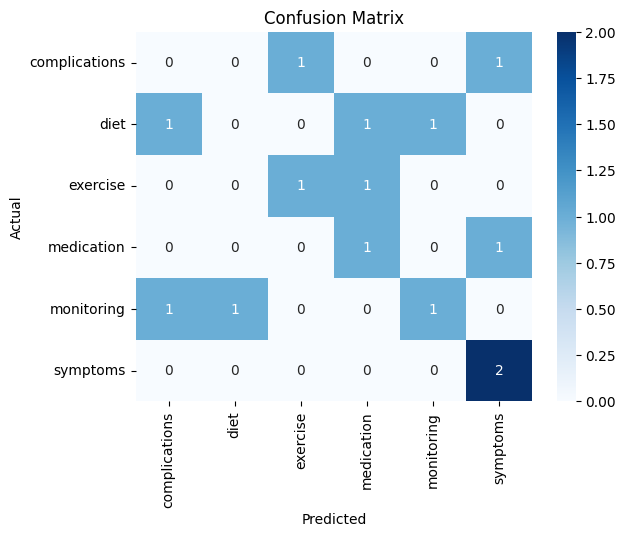

In [7]:
p, r, f, _ = precision_recall_fscore_support(y_te, y_pred, average="macro", zero_division=0)
print(f"Accuracy: {accuracy_score(y_te, y_pred):.2f}  Precision: {p:.2f}  Recall: {r:.2f}  F1: {f:.2f}\n")
print(classification_report(y_te, y_pred, zero_division=0))
cm = confusion_matrix(y_te, y_pred, labels=clf.classes_)
sns.heatmap(cm, annot=True, cmap="Blues", xticklabels=clf.classes_, yticklabels=clf.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix"); plt.show()

In [8]:
# retrain on full corpus for the assistant
vec = TfidfVectorizer(ngram_range=(1, 2))
X = vec.fit_transform(df.clean)
clf = LogisticRegression(max_iter=1000, C=10).fit(X, df.intent)

## 7. Knowledge Base

In [9]:
kb = {
    "symptoms": "Common diabetes symptoms: frequent urination, excessive thirst, increased hunger, fatigue, blurred vision, slow-healing wounds and unexplained weight loss. Low sugar (hypoglycemia) causes shaking, sweating, dizziness and confusion. Get a blood test to confirm.",
    "diet": "Eat high-fibre foods, whole grains, vegetables, lean protein and healthy fats. Limit sugary drinks, sweets, white rice/bread and fried food. Control portions, keep meals regular and prefer low-glycemic fruits like apples and berries.",
    "medication": "Common medicines: Metformin (first-line for type 2), sulfonylureas, DPP-4 inhibitors, SGLT2 inhibitors and insulin (rapid, short, intermediate, long-acting). Store unopened insulin in the fridge. Never change doses without your doctor.",
    "monitoring": "Normal fasting sugar: 70-99 mg/dL (80-130 target for diabetics). After meals: below 180 mg/dL. HbA1c shows 3-month average; target is usually below 7%. Use a glucometer or CGM and keep a log of readings.",
    "exercise": "Aim for 150 minutes/week of moderate activity (brisk walking, cycling, swimming) plus strength training twice a week. Check sugar before exercise, carry a quick sugar source and stay hydrated.",
    "complications": "Long-term high sugar can damage eyes (retinopathy), kidneys (nephropathy), nerves (neuropathy), heart and feet. Prevent them with good sugar control, yearly eye/kidney/foot checks, controlling BP and cholesterol, and not smoking.",
}

## 8. Rules & Reasoning

In [10]:
EMERGENCY = ["unconscious", "faint", "fainted", "seizure", "chest pain", "can't breathe", "cannot breathe",
             "not breathing", "very low sugar", "sugar is 40", "ketoacidosis", "dka", "vomiting", "confused", "collapsed"]
UNSUPPORTED = ["cancer", "covid", "fracture", "broken", "asthma", "migraine", "pregnancy", "tooth", "skin", "hair", "malaria"]
DOMAIN = r"\b(diabet|sugar|glucose|insulin|hba1c|metformin|carb|diet|eat|food|exercise|hypoglycemia)"
GREET = ["hi", "hello", "hey"]
THRESHOLD = 0.30

def assistant(q):
    ql = q.lower().strip()
    if not ql:                                         # Rule 1: empty input
        return "Please type a question."
    if any(e in ql for e in EMERGENCY):                # Rule 2: emergency escalation
        return "EMERGENCY: This may be a medical emergency. Call 112/108 or go to the nearest hospital now. If conscious and sugar is low, take 15g fast sugar (juice/glucose)."
    if ql in GREET:                                    # Rule 3: greeting
        return "Hello! Ask me anything about diabetes care."
    if any(u in ql for u in UNSUPPORTED) and not re.search(DOMAIN, ql):   # Rule 4: unsupported
        return "Sorry, I only handle diabetes-related queries. Please consult a doctor for this."
    clean = preprocess(ql)
    vecq = vec.transform([clean])
    if vecq.nnz == 0:                                  # Rule 5: no known terms -> unsupported
        return "Sorry, I couldn't understand that. I can help with diabetes symptoms, diet, medication, monitoring, exercise and complications."
    probs = clf.predict_proba(vecq)[0]
    intent, conf = clf.classes_[probs.argmax()], probs.max()
    if conf < THRESHOLD:                               # Rule 6: low confidence
        return f"I'm not sure what you mean (confidence {conf:.2f}). Could you rephrase? E.g. 'what should a diabetic eat'"
    ans = f"[{intent} | {conf:.2f}] {kb[intent]}"
    if intent == "medication":                         # Rule 7: medical disclaimer
        ans += "\nNote: Always consult your doctor before starting or changing medication."
    return ans

## 9. Testing

In [11]:
tests = {
    "Symptoms": "what are early symptoms of diabetes",
    "Diet": "which foods should diabetics avoid",
    "Medication": "side effects of metformin",
    "Monitoring": "what is a normal hba1c level",
    "Exercise": "is walking good for diabetics",
    "Complications": "can diabetes damage my eyes",
    "Different wording": "my glucose keeps going up, what food can i have",
    "Unsupported": "how to treat a broken arm",
    "Low confidence": "sugar and diet and medicine",
    "Emergency": "my father is unconscious and his sugar is very low",
}
for k, q in tests.items():
    print(f"{k}: {q}\n -> {assistant(q)}\n")

Symptoms: what are early symptoms of diabetes
 -> [symptoms | 0.72] Common diabetes symptoms: frequent urination, excessive thirst, increased hunger, fatigue, blurred vision, slow-healing wounds and unexplained weight loss. Low sugar (hypoglycemia) causes shaking, sweating, dizziness and confusion. Get a blood test to confirm.

Diet: which foods should diabetics avoid
 -> [diet | 0.52] Eat high-fibre foods, whole grains, vegetables, lean protein and healthy fats. Limit sugary drinks, sweets, white rice/bread and fried food. Control portions, keep meals regular and prefer low-glycemic fruits like apples and berries.

Medication: side effects of metformin
 -> [medication | 0.61] Common medicines: Metformin (first-line for type 2), sulfonylureas, DPP-4 inhibitors, SGLT2 inhibitors and insulin (rapid, short, intermediate, long-acting). Store unopened insulin in the fridge. Never change doses without your doctor.
Note: Always consult your doctor before starting or changing medication.

Moni

## 10. Interactive Assistant
Type `exit` to stop.

In [14]:
print("Diabetes Care Assistant (type 'exit' to quit)")
while True:
    q = input("You: ")
    if q.lower().strip() in ["exit", "quit", "bye"]:
        print("Bot: Take care!"); break
    print("Bot:", assistant(q), "\n")

Diabetes Care Assistant (type 'exit' to quit)
You: what should a diabetic eat
Bot: [diet | 0.50] Eat high-fibre foods, whole grains, vegetables, lean protein and healthy fats. Limit sugary drinks, sweets, white rice/bread and fried food. Control portions, keep meals regular and prefer low-glycemic fruits like apples and berries. 

You: early symptoms
Bot: [symptoms | 0.60] Common diabetes symptoms: frequent urination, excessive thirst, increased hunger, fatigue, blurred vision, slow-healing wounds and unexplained weight loss. Low sugar (hypoglycemia) causes shaking, sweating, dizziness and confusion. Get a blood test to confirm. 

You: exit
Bot: Take care!
